Praktikum 2 - Klasifikasi Naive Bayes pada data dummy (make_classification).

In [1]:
# Shim: notebook tidak punya __file__, kode ini warisan script .py.
import os
__file__ = os.path.abspath("naive_bayes_dummy.ipynb")
print("base:", os.path.dirname(__file__))

base: C:\code\pemmes26\js09-klasifikasi\praktikum-2


In [2]:
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import make_classification
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB, MultinomialNB

HERE = Path(__file__).resolve().parent
OUT = HERE / "output"
OUT.mkdir(exist_ok=True)

In [3]:
# Langkah 1 - Dataset dummy (random_state dipatok agar hasil reproducible)
X, y = make_classification(n_samples=30, n_features=2, n_classes=2,
                           n_informative=2, n_redundant=0, n_repeated=0,
                           shuffle=False, random_state=42)
X = np.round(np.absolute(X), 2) * 100   # diskritkan: 2 desimal -> integer
X = X.astype(int)
print("=== Langkah 1: Data Dummy ===")
print(X)
print(y)

=== Langkah 1: Data Dummy ===
[[112 139]
 [179 210]
 [ 83  71]
 [182 265]
 [105  78]
 [ 67  43]
 [ 36  54]
 [ 20  70]
 [122  70]
 [250  83]
 [ 50 142]
 [206 110]
 [115  84]
 [124  66]
 [150  85]
 [ 16  73]
 [ 46 113]
 [ 26  80]
 [ 18 114]
 [211 154]
 [ 53  66]
 [ 93 109]
 [175 172]
 [ 80  85]
 [111 125]
 [115 105]
 [ 66  92]
 [160  85]
 [ 53 106]
 [122  85]]
[0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 1 1 1 1 1 1 1]


In [4]:
# Langkah 2-3 - DataFrame + labeling
df = pd.DataFrame(np.concatenate((X, y.reshape(len(y), 1)), axis=1),
                  columns=["Fitur 1", "Fitur 2", "Label"])
df_label = df.copy()
df_label["Label"] = df_label["Label"].map({1: "Kelas A", 0: "Kelas B"})
print("\n=== Langkah 2-3: DataFrame ===")
print(df_label.head())
df_label.to_csv(OUT / "data_dummy.csv", index=False)


=== Langkah 2-3: DataFrame ===
   Fitur 1  Fitur 2    Label
0      112      139  Kelas B
1      179      210  Kelas B
2       83       71  Kelas B
3      182      265  Kelas B
4      105       78  Kelas B


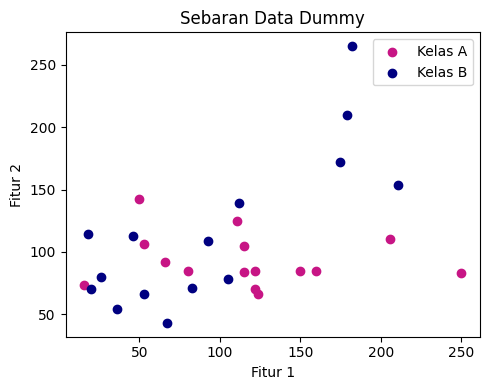

In [5]:
# Langkah 4 - Visualisasi sebaran data
colors = {"Kelas A": "MediumVioletRed", "Kelas B": "Navy"}
fig, ax = plt.subplots(figsize=(5, 4))
for label, grp in df_label.groupby("Label"):
    ax.scatter(grp["Fitur 1"], grp["Fitur 2"], c=colors[label], label=label)
ax.set(xlabel="Fitur 1", ylabel="Fitur 2", title="Sebaran Data Dummy")
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "sebaran_data_dummy.png", dpi=110)

In [6]:
# Split data (sama untuk kedua model)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=30)

In [7]:
# Langkah 5 - MultinomialNB
mnb = MultinomialNB().fit(X_train, y_train)
acc_train = accuracy_score(y_train, mnb.predict(X_train))
acc_test = accuracy_score(y_test, mnb.predict(X_test))
print("\n=== Langkah 5: MultinomialNB ===")
print(f"Hasil akurasi data train: {acc_train}")
print(f"Hasil akurasi data test: {acc_test}")


=== Langkah 5: MultinomialNB ===
Hasil akurasi data train: 0.8095238095238095
Hasil akurasi data test: 0.3333333333333333


In [8]:
# Langkah 6 - GaussianNB
gnb = GaussianNB().fit(X_train, y_train)
acc_train_g = accuracy_score(y_train, gnb.predict(X_train))
acc_test_g = accuracy_score(y_test, gnb.predict(X_test))
print("\n=== Langkah 6: GaussianNB ===")
print(f"Hasil akurasi data train (Gaussian): {acc_train_g}")
print(f"Hasil akurasi data test (Gaussian): {acc_test_g}")


=== Langkah 6: GaussianNB ===
Hasil akurasi data train (Gaussian): 0.8571428571428571
Hasil akurasi data test (Gaussian): 0.4444444444444444


In [9]:
# Evaluasi detail
for name, model in (("MultinomialNB", mnb), ("GaussianNB", gnb)):
    pred = model.predict(X_test)
    print(f"\n--- {name} ---")
    print("Confusion Matrix:\n", confusion_matrix(y_test, pred))
    print(classification_report(y_test, pred, digits=4, zero_division=0))


--- MultinomialNB ---
Confusion Matrix:
 [[2 0]
 [6 1]]
              precision    recall  f1-score   support

           0     0.2500    1.0000    0.4000         2
           1     1.0000    0.1429    0.2500         7

    accuracy                         0.3333         9
   macro avg     0.6250    0.5714    0.3250         9
weighted avg     0.8333    0.3333    0.2833         9


--- GaussianNB ---
Confusion Matrix:
 [[2 0]
 [5 2]]
              precision    recall  f1-score   support

           0     0.2857    1.0000    0.4444         2
           1     1.0000    0.2857    0.4444         7

    accuracy                         0.4444         9
   macro avg     0.6429    0.6429    0.4444         9
weighted avg     0.8413    0.4444    0.4444         9




Ringkasan akurasi uji: Multinomial=0.3333, Gaussian=0.4444


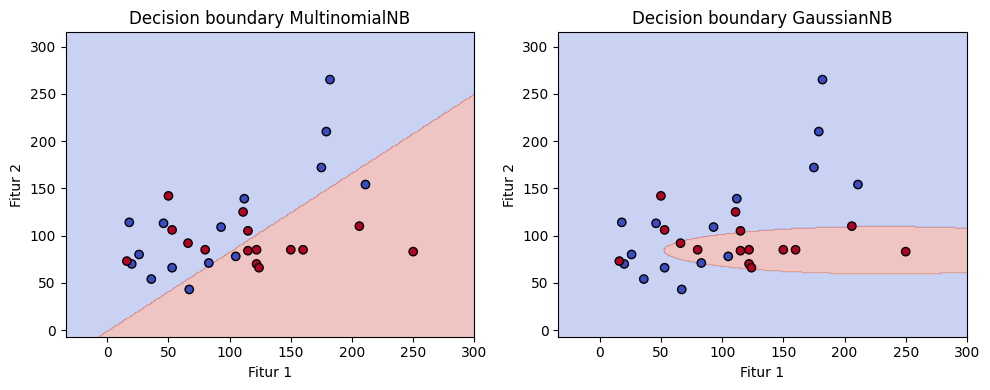

In [10]:
# Decision boundary kedua model pada ruang 2 fitur
xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - 50, X[:, 0].max() + 50, 300),
                     np.linspace(X[:, 1].min() - 50, X[:, 1].max() + 50, 300))
grid = np.c_[xx.ravel(), yy.ravel()]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, model) in zip(axes, (("MultinomialNB", mnb),
                                    ("GaussianNB", gnb))):
    zz = model.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, zz, alpha=.3, cmap="coolwarm")
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolor="k")
    ax.set(title=f"Decision boundary {name}", xlabel="Fitur 1",
           ylabel="Fitur 2")
fig.tight_layout()
fig.savefig(OUT / "decision_boundary_nb.png", dpi=110)

print("\nRingkasan akurasi uji: "
      f"Multinomial={acc_test:.4f}, Gaussian={acc_test_g:.4f}")

In [11]:
# Catatan: n=30 (uji hanya 9 sampel) -> akurasi sangat sensitif terhadap seed.
# Modul tidak memakai random_state; di sini dampak seed diukur eksplisit.
te_m, te_g = [], []
for seed in range(10):
    Xs, ys = make_classification(n_samples=30, n_features=2, n_classes=2,
                                 n_informative=2, n_redundant=0, n_repeated=0,
                                 shuffle=False, random_state=seed)
    Xs = (np.round(np.absolute(Xs), 2) * 100).astype(int)
    Xa, Xb, ya, yb = train_test_split(Xs, ys, test_size=0.3, random_state=30)
    te_m.append(accuracy_score(yb, MultinomialNB().fit(Xa, ya).predict(Xb)))
    te_g.append(accuracy_score(yb, GaussianNB().fit(Xa, ya).predict(Xb)))
print(f"10 seed -> akurasi uji MNB: {np.mean(te_m):.4f} +/- {np.std(te_m):.4f}"
      f" | GNB: {np.mean(te_g):.4f} +/- {np.std(te_g):.4f}")

10 seed -> akurasi uji MNB: 0.5444 +/- 0.2191 | GNB: 0.3778 +/- 0.1736
